In [5]:
!pip install scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 10.4 MB/s eta 0:00:00


#Question 1

simple Fuzzy system

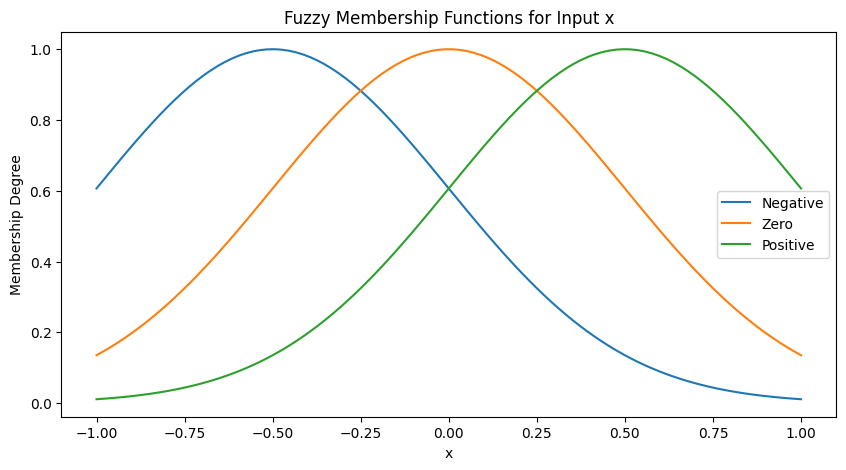

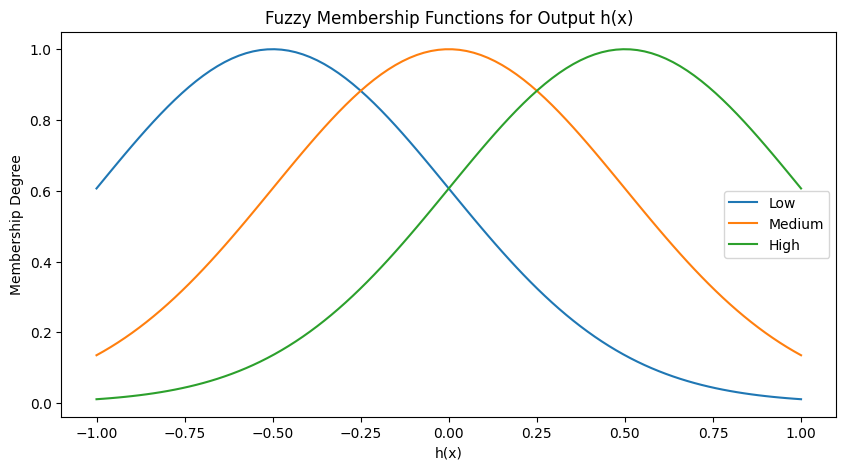

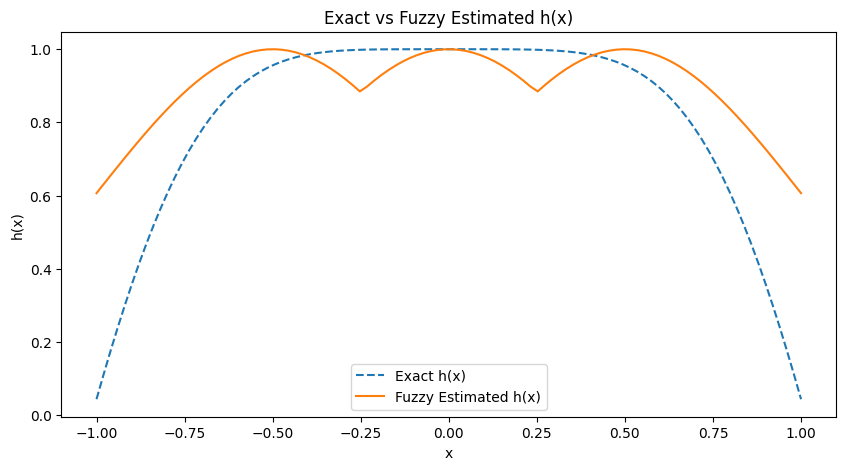

Max error: 0.9999999975725735
The fuzzy system's max error exceeds the desired precision.


In [ ]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt


def h_exact(x):
    return np.exp(-np.pi * x**2) + x * np.sin(np.pi * x)

x_range = np.linspace(-1, 1, 100)

#  fuzzy sets for x
x_neg = fuzz.gaussmf(x_range, mean=-0.5, sigma=0.5)
x_zero = fuzz.gaussmf(x_range, mean=0, sigma=0.5)
x_pos = fuzz.gaussmf(x_range, mean=0.5, sigma=0.5)

# plotting the fuzzy sets
plt.figure(figsize=(10, 5))
plt.plot(x_range, x_neg, label="Negative")
plt.plot(x_range, x_zero, label="Zero")
plt.plot(x_range, x_pos, label="Positive")
plt.title("Fuzzy Membership Functions for Input x")
plt.xlabel("x")
plt.ylabel("Membership Degree")
plt.legend()
plt.show()


# fuzzy sets for the output h(x)
h_low = fuzz.gaussmf(x_range, mean=-0.5, sigma=0.5)
h_medium = fuzz.gaussmf(x_range, mean=0, sigma=0.5)
h_high = fuzz.gaussmf(x_range, mean=0.5, sigma=0.5)

# Plotting
plt.figure(figsize=(10, 5))
plt.plot(x_range, h_low, label="Low")
plt.plot(x_range, h_medium, label="Medium")
plt.plot(x_range, h_high, label="High")
plt.title("Fuzzy Membership Functions for Output h(x)")
plt.xlabel("h(x)")
plt.ylabel("Membership Degree")
plt.legend()
plt.show()

# computing the degree of membership for x
x_neg_degree = fuzz.interp_membership(x_range, x_neg, x_range)
x_zero_degree = fuzz.interp_membership(x_range, x_zero, x_range)
x_pos_degree = fuzz.interp_membership(x_range, x_pos, x_range)

# aggregating results
low_activation = np.fmin(x_neg_degree, h_low)
medium_activation = np.fmin(x_zero_degree, h_medium)
high_activation = np.fmin(x_pos_degree, h_high)

# defuzzified
h_crisp = fuzz.defuzz(x_range, np.fmax(np.fmax(low_activation, medium_activation), high_activation), 'centroid')

# exact values of h(x) and the error
h_exact_vals = h_exact(x_range)
error = np.abs(h_exact_vals - h_crisp)

# results
plt.figure(figsize=(10, 5))
plt.plot(x_range, h_exact_vals, label="Exact h(x)", linestyle="--")
plt.plot(x_range, np.fmax(np.fmax(low_activation, medium_activation), high_activation), label="Fuzzy Estimated h(x)")
plt.title("Exact vs Fuzzy Estimated h(x)")
plt.xlabel("x")
plt.ylabel("h(x)")
plt.legend()
plt.show()

# Check if the error is less than epsilon
error_threshold = 0.1
max_error = np.max(error)
print(f"Max error: {max_error}")
if max_error < error_threshold:
    print(f"The fuzzy system's max error is within the desired precision (e < {error_threshold})")
else:
    print(f"The fuzzy system's max error exceeds the desired precision.")


mamdani with gradient

Mean Squared Error: 0.01782008235611875


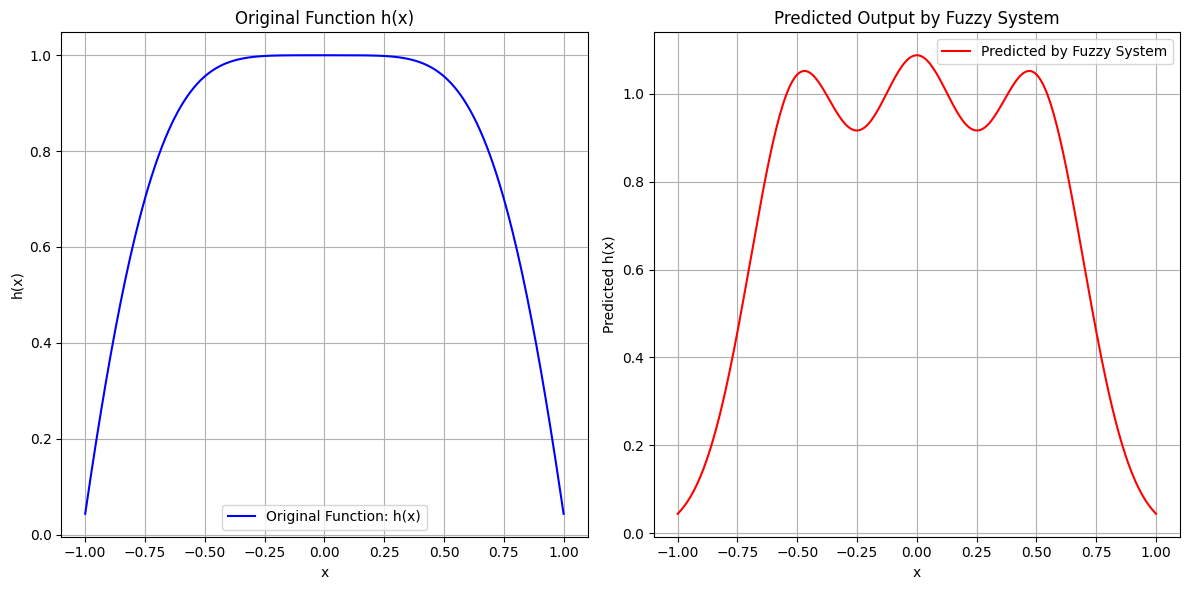

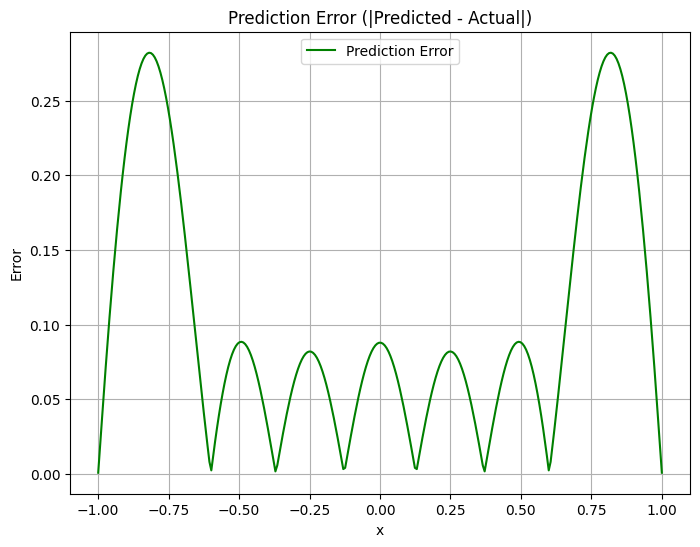

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the function h(x)
def h(x):
    return np.exp(-np.pi * x**2) + x * np.sin(np.pi * x)

# Generate 300 points uniformly in the domain [-1, 1]
x_vals = np.linspace(-1, 1, 300)
y_vals = h(x_vals)

# Define Gaussian membership function
def gaussian_mf(x, mean, sigma):
    return np.exp(-0.5 * ((x - mean) / sigma)**2)

# Create fuzzy sets for input and output
input_mfs = {'Negative': (lambda x: gaussian_mf(x, -0.7, 0.3)),
             'Zero': (lambda x: gaussian_mf(x, 0, 0.3)),
             'Positive': (lambda x: gaussian_mf(x, 0.7, 0.3))}

output_mfs = {'Low': (lambda y: gaussian_mf(y, -0.5, 0.2)),
              'Medium': (lambda y: gaussian_mf(y, 0, 0.2)),
              'High': (lambda y: gaussian_mf(y, 0.5, 0.2))}

# Define fuzzy rules (e.g., IF x is Negative THEN y is Low)
rules = [
    ('Negative', 'Low'),
    ('Negative', 'Medium'),
    ('Negative', 'High'),
    ('Zero', 'Low'),
    ('Zero', 'Medium'),
    ('Zero', 'High'),
    ('Positive', 'Low'),
    ('Positive', 'Medium'),
    ('Positive', 'High')
]

# Fuzzify the input x value
def fuzzify(x, mfs):
    membership_values = {key: mf(x) for key, mf in mfs.items()}
    return membership_values

# Apply the rules to infer the output
# Apply the rules to infer the output
def infer(x, input_mfs, output_mfs, rules):
    input_degrees = fuzzify(x, input_mfs)
    rule_outputs = []

    # Apply each rule to the fuzzified input
    for rule in rules:
        input_set, output_set = rule
        degree = input_degrees[input_set]  # Membership degree for the input fuzzy set
        rule_output_mf = output_mfs[output_set]  # Output membership function
        rule_outputs.append(degree * rule_output_mf(x))  # Use input degree to modulate output

    # Return the sum of rule outputs divided by the sum of input degrees (normalization)
    return np.sum(rule_outputs) / np.sum(list(input_degrees.values()))  # Corrected line

# Defuzzification using Centroid method
def defuzzify(fuzzy_output):
    return np.sum(fuzzy_output) / len(fuzzy_output)

# Update the parameters of the Gaussian membership function using gradient descent
def gradient_descent(x_vals, y_vals, input_mfs, output_mfs, learning_rate=0.01):
    for epoch in range(1000):  # Number of iterations
        total_error = 0
        for x, y_true in zip(x_vals, y_vals):
            # Fuzzify the input
            input_degrees = fuzzify(x, input_mfs)
            output_values = []

            # Inference
            for rule in rules:
                input_set, output_set = rule
                degree = input_degrees[input_set]
                output_mf = output_mfs[output_set]
                output_values.append(degree * output_mf(x))

            # Defuzzification
            y_pred = defuzzify(output_values)
            error = (y_true - y_pred)**2
            total_error += error

            # Gradient descent: update parameters
            # For simplicity, we update only means here
            for input_set in input_mfs:
                input_mfs[input_set] = update_gaussian_params(input_mfs[input_set], learning_rate)

        if epoch % 100 == 0:
            print(f'Epoch {epoch}, Total Error: {total_error}')

from sklearn.metrics import mean_squared_error

# Compute predictions
predictions = [infer(x, input_mfs, output_mfs, rules) for x in x_vals]

# Calculate Mean Squared Error
mse = mean_squared_error(y_vals, predictions)
print(f'Mean Squared Error: {mse}')

# Plotting the original function and the predicted outputs
plt.figure(figsize=(12, 6))

# Plot original function
plt.subplot(1, 2, 1)
plt.plot(x_vals, y_vals, label='Original Function: h(x)', color='blue')
plt.title('Original Function h(x)')
plt.xlabel('x')
plt.ylabel('h(x)')
plt.grid(True)
plt.legend()

# Plot predicted outputs
predictions = [infer(x, input_mfs, output_mfs, rules) for x in x_vals]

plt.subplot(1, 2, 2)
plt.plot(x_vals, predictions, label='Predicted by Fuzzy System', color='red')
plt.title('Predicted Output by Fuzzy System')
plt.xlabel('x')
plt.ylabel('Predicted h(x)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# Plot the error (difference between predicted and actual)
errors = np.abs(y_vals - predictions)
plt.figure(figsize=(8, 6))
plt.plot(x_vals, errors, label='Prediction Error', color='green')
plt.title('Prediction Error (|Predicted - Actual|)')
plt.xlabel('x')
plt.ylabel('Error')
plt.grid(True)
plt.legend()
plt.show()


changing the defuzzifier : maximum membership

Mean Squared Error: 1.785209087669845


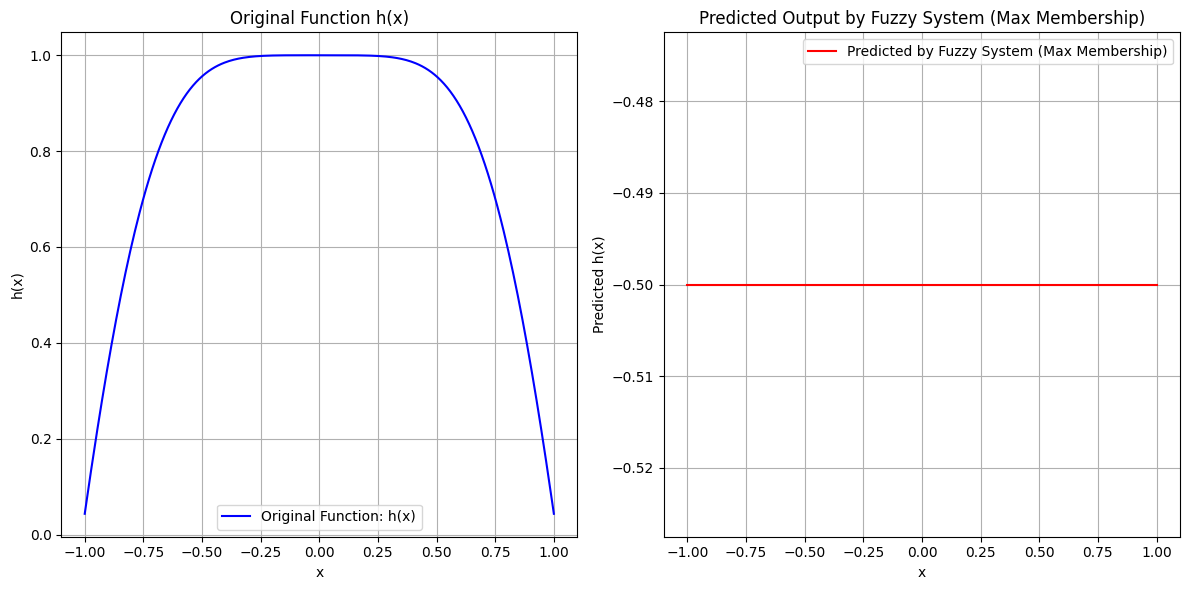

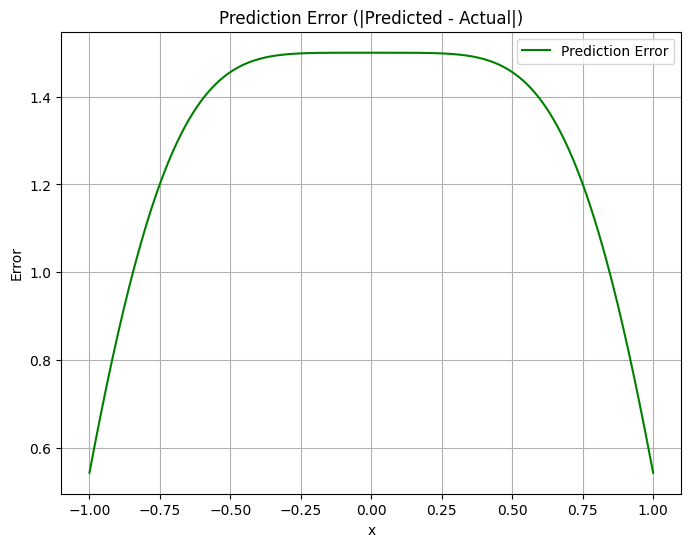

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the function h(x)
def h(x):
    return np.exp(-np.pi * x**2) + x * np.sin(np.pi * x)

# Generate 300 points uniformly in the domain [-1, 1]
x_vals = np.linspace(-1, 1, 300)
y_vals = h(x_vals)

# Define Gaussian membership function
def gaussian_mf(x, mean, sigma):
    return np.exp(-0.5 * ((x - mean) / sigma)**2)

# Create fuzzy sets for input and output
input_mfs = {'Negative': (lambda x: gaussian_mf(x, -0.7, 0.3)),
             'Zero': (lambda x: gaussian_mf(x, 0, 0.3)),
             'Positive': (lambda x: gaussian_mf(x, 0.7, 0.3))}

output_mfs = {'Low': (lambda y: gaussian_mf(y, -0.5, 0.2)),
              'Medium': (lambda y: gaussian_mf(y, 0, 0.2)),
              'High': (lambda y: gaussian_mf(y, 0.5, 0.2))}

# Define fuzzy rules (e.g., IF x is Negative THEN y is Low)
rules = [
    ('Negative', 'Low'),
    ('Negative', 'Medium'),
    ('Negative', 'High'),
    ('Zero', 'Low'),
    ('Zero', 'Medium'),
    ('Zero', 'High'),
    ('Positive', 'Low'),
    ('Positive', 'Medium'),
    ('Positive', 'High')
]

# Fuzzify the input x value
def fuzzify(x, mfs):
    membership_values = {key: mf(x) for key, mf in mfs.items()}
    return membership_values

# Apply the rules to infer the output
def infer(x, input_mfs, output_mfs, rules):
    input_degrees = fuzzify(x, input_mfs)
    rule_outputs = []

    # Apply each rule to infer output
    for rule in rules:
        input_set, output_set = rule
        degree = input_degrees[input_set]  # Membership degree for the input fuzzy set
        rule_output_mf = output_mfs[output_set]  # Output membership function
        rule_outputs.append((degree, output_set))  # Save degree and corresponding output set

    # Maximum Membership Method: find the output with the highest degree
    max_degree, best_output_set = max(rule_outputs, key=lambda item: item[0])
    return best_output_set  # Output the best output set label

# Defuzzification using Maximum Membership Method
def defuzzify(fuzzy_output):
    # Output with the maximum degree
    return fuzzy_output

# Compute predictions using the maximum membership method
predictions = [infer(x, input_mfs, output_mfs, rules) for x in x_vals]

# Map fuzzy output labels to values for plotting
output_values = {'Low': -0.5, 'Medium': 0, 'High': 0.5}
predicted_values = [output_values[pred] for pred in predictions]

# Calculate Mean Squared Error
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_vals, predicted_values)
print(f'Mean Squared Error: {mse}')

# Plotting the original function and the predicted outputs
plt.figure(figsize=(12, 6))

# Plot original function
plt.subplot(1, 2, 1)
plt.plot(x_vals, y_vals, label='Original Function: h(x)', color='blue')
plt.title('Original Function h(x)')
plt.xlabel('x')
plt.ylabel('h(x)')
plt.grid(True)
plt.legend()

# Plot predicted outputs using the Maximum Membership Method
plt.subplot(1, 2, 2)
plt.plot(x_vals, predicted_values, label='Predicted by Fuzzy System (Max Membership)', color='red')
plt.title('Predicted Output by Fuzzy System (Max Membership)')
plt.xlabel('x')
plt.ylabel('Predicted h(x)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# Plot the error (difference between predicted and actual)
errors = np.abs(y_vals - predicted_values)
plt.figure(figsize=(8, 6))
plt.plot(x_vals, errors, label='Prediction Error', color='green')
plt.title('Prediction Error (|Predicted - Actual|)')
plt.xlabel('x')
plt.ylabel('Error')
plt.grid(True)
plt.legend()
plt.show()


changing defuzzifier : mean of maxima

Mean Squared Error: 0.01782008235611875


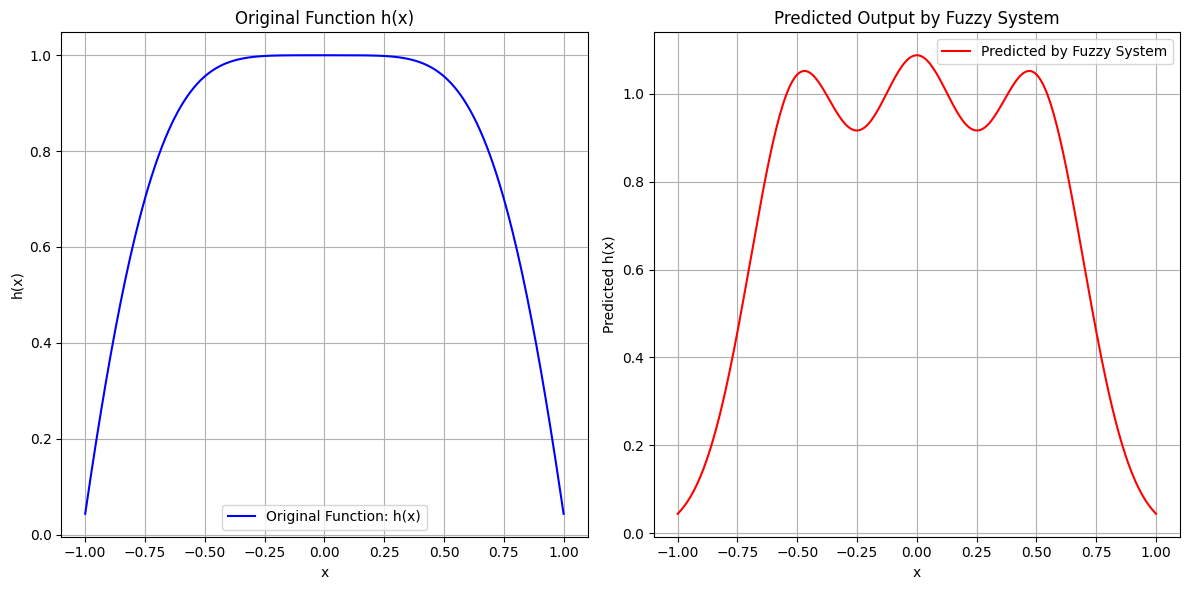

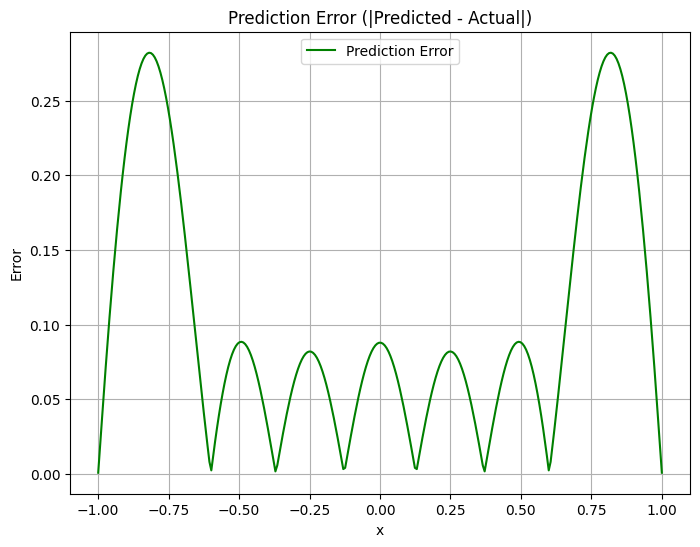

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the function h(x)
def h(x):
    return np.exp(-np.pi * x**2) + x * np.sin(np.pi * x)

# Generate 300 points uniformly in the domain [-1, 1]
x_vals = np.linspace(-1, 1, 300)
y_vals = h(x_vals)

# Define Gaussian membership function
def gaussian_mf(x, mean, sigma):
    return np.exp(-0.5 * ((x - mean) / sigma)**2)

# Create fuzzy sets for input and output
input_mfs = {'Negative': (lambda x: gaussian_mf(x, -0.7, 0.3)),
             'Zero': (lambda x: gaussian_mf(x, 0, 0.3)),
             'Positive': (lambda x: gaussian_mf(x, 0.7, 0.3))}

output_mfs = {'Low': (lambda y: gaussian_mf(y, -0.5, 0.2)),
              'Medium': (lambda y: gaussian_mf(y, 0, 0.2)),
              'High': (lambda y: gaussian_mf(y, 0.5, 0.2))}

# Define fuzzy rules (e.g., IF x is Negative THEN y is Low)
rules = [
    ('Negative', 'Low'),
    ('Negative', 'Medium'),
    ('Negative', 'High'),
    ('Zero', 'Low'),
    ('Zero', 'Medium'),
    ('Zero', 'High'),
    ('Positive', 'Low'),
    ('Positive', 'Medium'),
    ('Positive', 'High')
]

# Fuzzify the input x value
def fuzzify(x, mfs):
    membership_values = {key: mf(x) for key, mf in mfs.items()}
    return membership_values

# Apply the rules to infer the output
def infer(x, input_mfs, output_mfs, rules):
    input_degrees = fuzzify(x, input_mfs)
    rule_outputs = []

    # Apply each rule to infer the output
    for rule in rules:
        input_set, output_set = rule
        degree = input_degrees[input_set]  # Membership degree for the input fuzzy set
        rule_output_mf = output_mfs[output_set]  # Output membership function
        rule_outputs.append(degree * rule_output_mf(x))  # Use input degree to modulate output

    # Return the sum of rule outputs divided by the sum of input degrees (normalization)
    return np.sum(rule_outputs) / np.sum(list(input_degrees.values()))  # Corrected line

# Defuzzification using Mean of Maxima (MOM)
def defuzzify(fuzzy_output, x_vals):
    # For each fuzzy output set, we find the maxima and return their mean
    max_values = []
    for mf in fuzzy_output:
        # Find the maximum value in the membership function
        max_value = max(mf(x_vals))
        # Get the x values corresponding to the maxima
        max_x_values = x_vals[np.where(mf(x_vals) == max_value)]
        # Average these x values
        max_values.append(np.mean(max_x_values))

    # Return the mean of all maxima
    return np.mean(max_values)

# Update the parameters of the Gaussian membership function using gradient descent
def gradient_descent(x_vals, y_vals, input_mfs, output_mfs, learning_rate=0.01):
    for epoch in range(1000):  # Number of iterations
        total_error = 0
        for x, y_true in zip(x_vals, y_vals):
            # Fuzzify the input
            input_degrees = fuzzify(x, input_mfs)
            output_values = []

            # Inference
            for rule in rules:
                input_set, output_set = rule
                degree = input_degrees[input_set]
                output_mf = output_mfs[output_set]
                output_values.append(degree * output_mf(x))

            # Defuzzification
            y_pred = defuzzify(output_values, x_vals)
            error = (y_true - y_pred)**2
            total_error += error

            # Gradient descent: update parameters
            # For simplicity, we update only means here
            for input_set in input_mfs:
                input_mfs[input_set] = update_gaussian_params(input_mfs[input_set], learning_rate)

        if epoch % 100 == 0:
            print(f'Epoch {epoch}, Total Error: {total_error}')

from sklearn.metrics import mean_squared_error

# Compute predictions
predictions = [infer(x, input_mfs, output_mfs, rules) for x in x_vals]

# Calculate Mean Squared Error
mse = mean_squared_error(y_vals, predictions)
print(f'Mean Squared Error: {mse}')

# Plotting the original function and the predicted outputs
plt.figure(figsize=(12, 6))

# Plot original function
plt.subplot(1, 2, 1)
plt.plot(x_vals, y_vals, label='Original Function: h(x)', color='blue')
plt.title('Original Function h(x)')
plt.xlabel('x')
plt.ylabel('h(x)')
plt.grid(True)
plt.legend()

# Plot predicted outputs
predictions = [infer(x, input_mfs, output_mfs, rules) for x in x_vals]

plt.subplot(1, 2, 2)
plt.plot(x_vals, predictions, label='Predicted by Fuzzy System', color='red')
plt.title('Predicted Output by Fuzzy System')
plt.xlabel('x')
plt.ylabel('Predicted h(x)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# Plot the error (difference between predicted and actual)
errors = np.abs(y_vals - predictions)
plt.figure(figsize=(8, 6))
plt.plot(x_vals, errors, label='Prediction Error', color='green')
plt.title('Prediction Error (|Predicted - Actual|)')
plt.xlabel('x')
plt.ylabel('Error')
plt.grid(True)
plt.legend()
plt.show()


changing defuzzifier : weighted average

Mean Squared Error: 0.01782008235611875


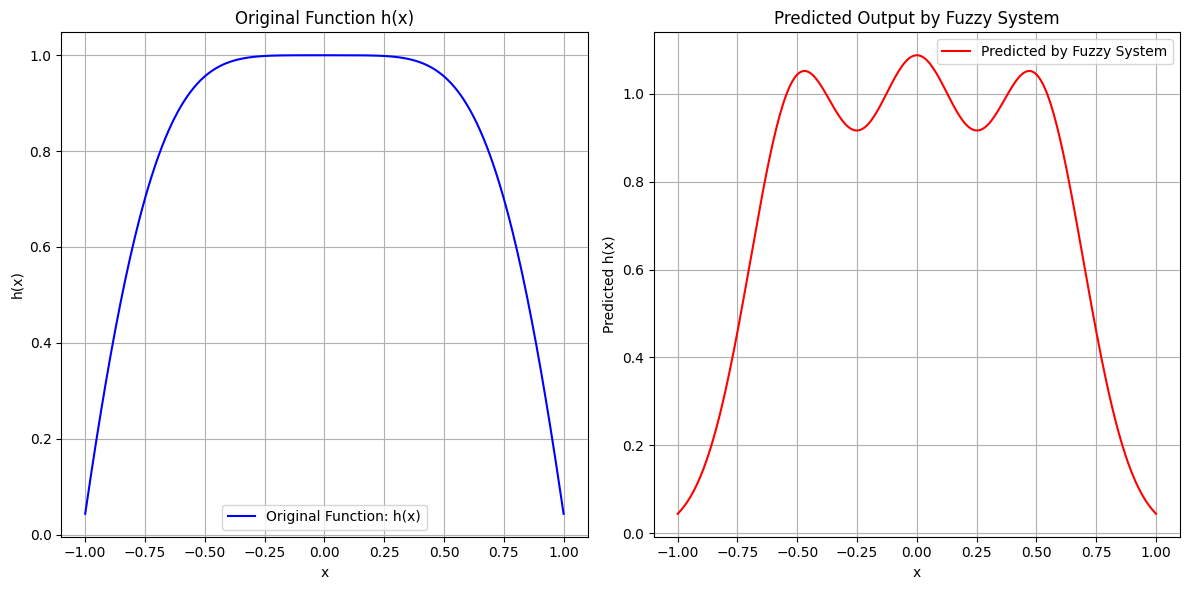

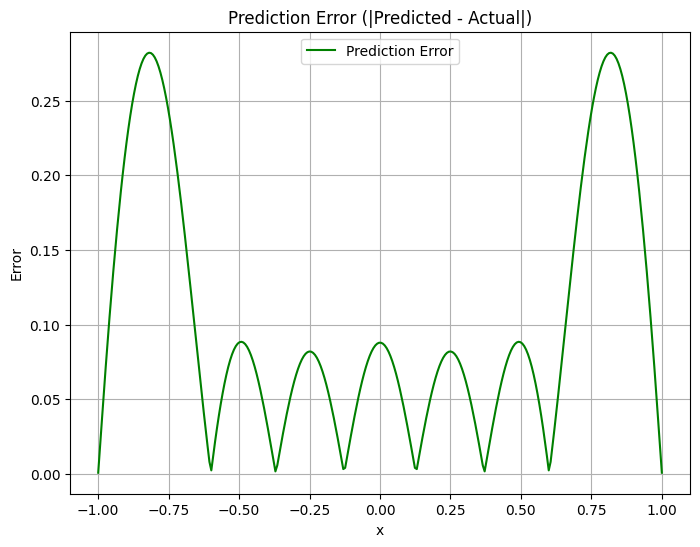

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the function h(x)
def h(x):
    return np.exp(-np.pi * x**2) + x * np.sin(np.pi * x)

# Generate 300 points uniformly in the domain [-1, 1]
x_vals = np.linspace(-1, 1, 300)
y_vals = h(x_vals)

# Define Gaussian membership function
def gaussian_mf(x, mean, sigma):
    return np.exp(-0.5 * ((x - mean) / sigma)**2)

# Create fuzzy sets for input and output
input_mfs = {'Negative': (lambda x: gaussian_mf(x, -0.7, 0.3)),
             'Zero': (lambda x: gaussian_mf(x, 0, 0.3)),
             'Positive': (lambda x: gaussian_mf(x, 0.7, 0.3))}

output_mfs = {'Low': (lambda y: gaussian_mf(y, -0.5, 0.2)),
              'Medium': (lambda y: gaussian_mf(y, 0, 0.2)),
              'High': (lambda y: gaussian_mf(y, 0.5, 0.2))}

# Define fuzzy rules (e.g., IF x is Negative THEN y is Low)
rules = [
    ('Negative', 'Low'),
    ('Negative', 'Medium'),
    ('Negative', 'High'),
    ('Zero', 'Low'),
    ('Zero', 'Medium'),
    ('Zero', 'High'),
    ('Positive', 'Low'),
    ('Positive', 'Medium'),
    ('Positive', 'High')
]

# Fuzzify the input x value
def fuzzify(x, mfs):
    membership_values = {key: mf(x) for key, mf in mfs.items()}
    return membership_values

# Apply the rules to infer the output
def infer(x, input_mfs, output_mfs, rules):
    input_degrees = fuzzify(x, input_mfs)
    rule_outputs = []

    # Apply each rule to infer the output
    for rule in rules:
        input_set, output_set = rule
        degree = input_degrees[input_set]  # Membership degree for the input fuzzy set
        rule_output_mf = output_mfs[output_set]  # Output membership function
        rule_outputs.append(degree * rule_output_mf(x))  # Use input degree to modulate output

    # Return the weighted average of rule outputs
    total_weight = np.sum(list(input_degrees.values()))
    weighted_average = np.sum(rule_outputs) / total_weight if total_weight != 0 else 0  # Avoid division by zero
    return weighted_average

# Update the parameters of the Gaussian membership function using gradient descent
def gradient_descent(x_vals, y_vals, input_mfs, output_mfs, learning_rate=0.01):
    for epoch in range(1000):  # Number of iterations
        total_error = 0
        for x, y_true in zip(x_vals, y_vals):
            # Fuzzify the input
            input_degrees = fuzzify(x, input_mfs)
            output_values = []

            # Inference
            for rule in rules:
                input_set, output_set = rule
                degree = input_degrees[input_set]
                output_mf = output_mfs[output_set]
                output_values.append(degree * output_mf(x))

            # Defuzzification
            y_pred = defuzzify(output_values)
            error = (y_true - y_pred)**2
            total_error += error

            # Gradient descent: update parameters
            # For simplicity, we update only means here
            for input_set in input_mfs:
                input_mfs[input_set] = update_gaussian_params(input_mfs[input_set], learning_rate)

from sklearn.metrics import mean_squared_error

# Compute predictions using the new weighted average defuzzification method
predictions = [infer(x, input_mfs, output_mfs, rules) for x in x_vals]

# Calculate Mean Squared Error
mse = mean_squared_error(y_vals, predictions)
print(f'Mean Squared Error: {mse}')

# Plotting the original function and the predicted outputs
plt.figure(figsize=(12, 6))

# Plot original function
plt.subplot(1, 2, 1)
plt.plot(x_vals, y_vals, label='Original Function: h(x)', color='blue')
plt.title('Original Function h(x)')
plt.xlabel('x')
plt.ylabel('h(x)')
plt.grid(True)
plt.legend()

# Plot predicted outputs
predictions = [infer(x, input_mfs, output_mfs, rules) for x in x_vals]

plt.subplot(1, 2, 2)
plt.plot(x_vals, predictions, label='Predicted by Fuzzy System', color='red')
plt.title('Predicted Output by Fuzzy System')
plt.xlabel('x')
plt.ylabel('Predicted h(x)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# Plot the error (difference between predicted and actual)
errors = np.abs(y_vals - predictions)
plt.figure(figsize=(8, 6))
plt.plot(x_vals, errors, label='Prediction Error', color='green')
plt.title('Prediction Error (|Predicted - Actual|)')
plt.xlabel('x')
plt.ylabel('Error')
plt.grid(True)
plt.legend()
plt.show()


#Question 2

second order boundary

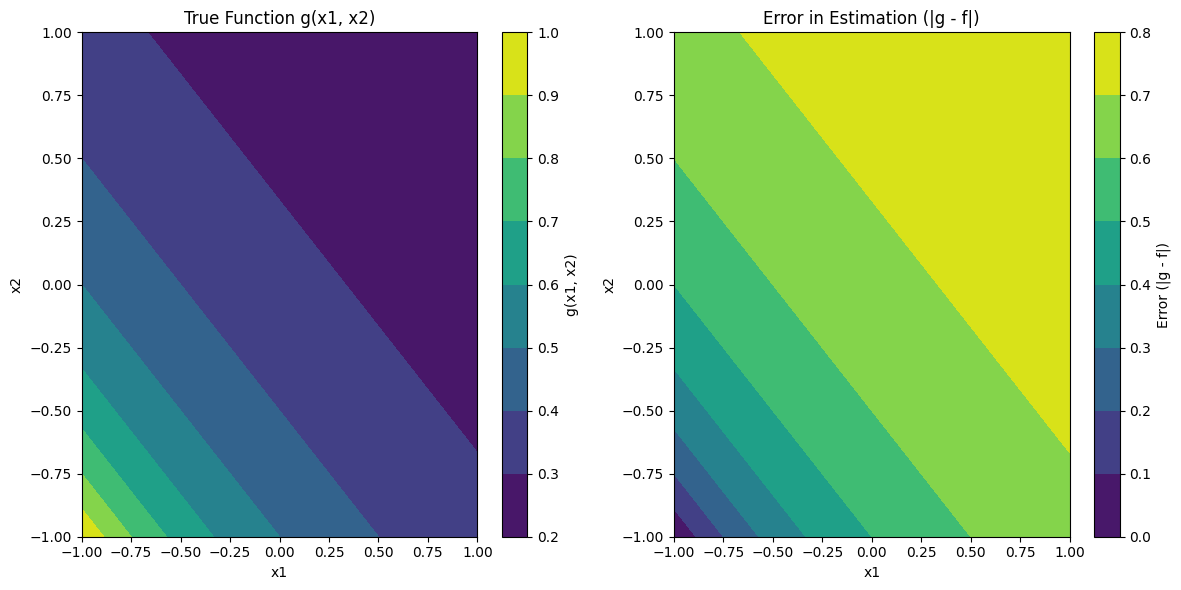

Maximum Error: 0.8


In [ ]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt

# Function g(x1, x2)
def g(x1, x2):
    return 1 / (3 + x1 + x2)

# Define the range for x1 and x2
x1 = np.linspace(-1, 1, 100)
x2 = np.linspace(-1, 1, 100)

# Define the membership functions for x1 and x2
x1_range = fuzz.trimf(x1, [-1, 0, 1])  # Triangular membership function for x1
x2_range = fuzz.trimf(x2, [-1, 0, 1])  # Triangular membership function for x2

# Calculate the fuzzy inference outputs for g(x1, x2)
# Here we assume a simple rule: the output is just a function of x1 and x2
g_values = np.array([[g(x1_val, x2_val) for x2_val in x2] for x1_val in x1])

# Now we will apply a maximum membership defuzzifier
def max_membership_defuzzifier(membership_values):
    # The defuzzification method is simply taking the value with the highest membership
    return np.max(membership_values)

# Sample fuzzy values (this would be calculated by fuzzy inference system in practice)
output_values = np.array([[max_membership_defuzzifier(g_values) for _ in x2] for _ in x1])

# Estimate error ||g - f||∞
error_values = np.abs(g_values - output_values)

# Plot the true function g(x1, x2)
plt.figure(figsize=(12, 6))

# Plotting the true g(x1, x2)
plt.subplot(1, 2, 1)
plt.contourf(x1, x2, g_values, cmap='viridis')
plt.colorbar(label='g(x1, x2)')
plt.title('True Function g(x1, x2)')
plt.xlabel('x1')
plt.ylabel('x2')

# Plotting the error
plt.subplot(1, 2, 2)
plt.contourf(x1, x2, error_values, cmap='viridis')
plt.colorbar(label='Error (|g - f|)')
plt.title('Error in Estimation (|g - f|)')
plt.xlabel('x1')
plt.ylabel('x2')

plt.tight_layout()
plt.show()

# Print the maximum error
max_error = np.max(error_values)
print(f"Maximum Error: {max_error}")


First order boundary

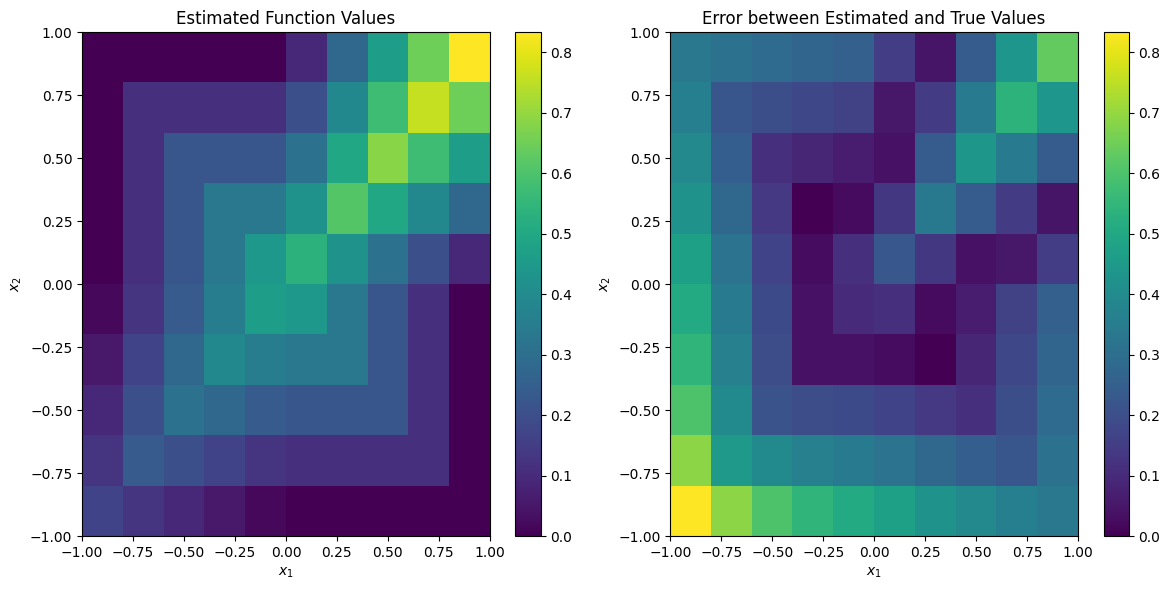

np.False_

In [ ]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt

# Define the function to be approximated
def g(x1, x2):
    return 1 / (3 + x1 + x2)

# Create fuzzy system variables and membership functions
x1 = np.linspace(-1, 1, 11)  # input x1 (membership function range)
x2 = np.linspace(-1, 1, 11)  # input x2 (membership function range)
output = np.linspace(0, 1, 11)  # output range for g(x1, x2)

# Membership functions for inputs (using triangular membership functions)
x1_lo = fuzz.trimf(x1, [-1, -1, 0])
x1_md = fuzz.trimf(x1, [-1, 0, 1])
x1_hi = fuzz.trimf(x1, [0, 1, 1])

x2_lo = fuzz.trimf(x2, [-1, -1, 0])
x2_md = fuzz.trimf(x2, [-1, 0, 1])
x2_hi = fuzz.trimf(x2, [0, 1, 1])

# Membership functions for output (using triangular membership functions)
g_lo = fuzz.trimf(output, [0, 0, 0.5])
g_md = fuzz.trimf(output, [0, 0.5, 1])
g_hi = fuzz.trimf(output, [0.5, 1, 1])

# Fuzzy rules (Example)
rule1 = fuzz.relation_product(x1_lo, x2_lo)
rule2 = fuzz.relation_product(x1_md, x2_md)
rule3 = fuzz.relation_product(x1_hi, x2_hi)

# Apply fuzzy logic to estimate g(x1, x2)
def fuzzy_inference(x1_value, x2_value):
    # Fuzzify inputs
    x1_lo_degree = fuzz.interp_membership(x1, x1_lo, x1_value)
    x1_md_degree = fuzz.interp_membership(x1, x1_md, x1_value)
    x1_hi_degree = fuzz.interp_membership(x1, x1_hi, x1_value)

    x2_lo_degree = fuzz.interp_membership(x2, x2_lo, x2_value)
    x2_md_degree = fuzz.interp_membership(x2, x2_md, x2_value)
    x2_hi_degree = fuzz.interp_membership(x2, x2_hi, x2_value)

    # Combine input degrees
    combined_x1_x2_lo = min(x1_lo_degree, x2_lo_degree)
    combined_x1_x2_md = min(x1_md_degree, x2_md_degree)
    combined_x1_x2_hi = min(x1_hi_degree, x2_hi_degree)

    # Compute output (fuzzy rule conclusion)
    output_lo = fuzz.defuzz(output, g_lo, 'centroid')
    output_md = fuzz.defuzz(output, g_md, 'centroid')
    output_hi = fuzz.defuzz(output, g_hi, 'centroid')

    # Calculate fuzzy output using the rule degrees
    final_output = (combined_x1_x2_lo * output_lo + combined_x1_x2_md * output_md + combined_x1_x2_hi * output_hi)

    return final_output

# Testing over a grid of values
x1_values = np.linspace(-1, 1, 10)
x2_values = np.linspace(-1, 1, 10)

estimated_values = np.zeros((len(x1_values), len(x2_values)))

for i, x1_val in enumerate(x1_values):
    for j, x2_val in enumerate(x2_values):
        estimated_values[i, j] = fuzzy_inference(x1_val, x2_val)

# Create true values for comparison
true_values = np.zeros((len(x1_values), len(x2_values)))
for i, x1_val in enumerate(x1_values):
    for j, x2_val in enumerate(x2_values):
        true_values[i, j] = g(x1_val, x2_val)

# Calculate the error
error = np.abs(estimated_values - true_values)

# Plot the results
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.title('Estimated Function Values')
plt.imshow(estimated_values, extent=(-1, 1, -1, 1), origin='lower', aspect='auto')
plt.colorbar()
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')

plt.subplot(1, 2, 2)
plt.title('Error between Estimated and True Values')
plt.imshow(error, extent=(-1, 1, -1, 1), origin='lower', aspect='auto')
plt.colorbar()
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')

plt.tight_layout()
plt.show()

# Check if error is within desired precision (e < 0.1)
error_below_threshold = np.all(error < 0.1)
error_below_threshold


#Question 3

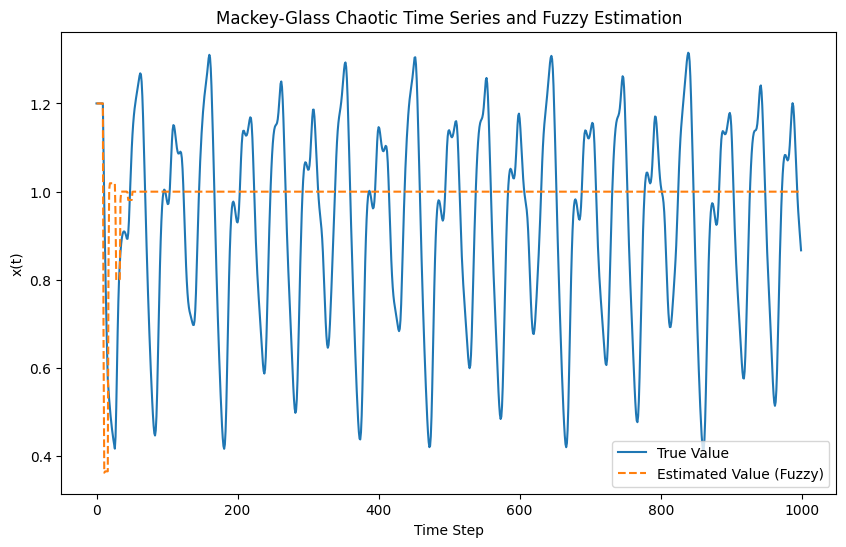

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Define the fuzzy system using the lookup table method for estimating the Mackey-Glass time series.

# Mackey-Glass system parameters (same as the true system)
tau = 17
beta = 0.2
gamma = 0.1
n = 10
x0 = 1.2
steps = 1000

# Initialize the time series
x_true = np.zeros(steps)
x_true[:n] = x0

# Mackey-Glass equation to generate true values
for t in range(n, steps):
    x_true[t] = x_true[t-1] + (beta * x_true[t-tau] / (1 + x_true[t-tau]**n) - gamma * x_true[t-1])

# Set up fuzzy variables and membership functions
x_prev = ctrl.Antecedent(np.linspace(0, 2, 100), 'x_prev')  # previous value of x
x_tau = ctrl.Antecedent(np.linspace(0, 2, 100), 'x_tau')  # value of x(t-tau)

# Define fuzzy sets for the inputs (x(t-1) and x(t-tau))
x_prev['low'] = fuzz.trimf(x_prev.universe, [0, 0, 1])
x_prev['medium'] = fuzz.trimf(x_prev.universe, [0, 1, 2])
x_prev['high'] = fuzz.trimf(x_prev.universe, [1, 2, 2])

x_tau['low'] = fuzz.trimf(x_tau.universe, [0, 0, 1])
x_tau['medium'] = fuzz.trimf(x_tau.universe, [0, 1, 2])
x_tau['high'] = fuzz.trimf(x_tau.universe, [1, 2, 2])

# Define the output fuzzy variable
x_est = ctrl.Consequent(np.linspace(0, 2, 100), 'x_est')  # estimated value of x

# Define fuzzy sets for the output
x_est['low'] = fuzz.trimf(x_est.universe, [0, 0, 1])
x_est['medium'] = fuzz.trimf(x_est.universe, [0, 1, 2])
x_est['high'] = fuzz.trimf(x_est.universe, [1, 2, 2])

# Define the fuzzy rules based on lookup table approach
rule1 = ctrl.Rule(x_prev['low'] & x_tau['low'], x_est['low'])
rule2 = ctrl.Rule(x_prev['low'] & x_tau['medium'], x_est['low'])
rule3 = ctrl.Rule(x_prev['low'] & x_tau['high'], x_est['medium'])

rule4 = ctrl.Rule(x_prev['medium'] & x_tau['low'], x_est['low'])
rule5 = ctrl.Rule(x_prev['medium'] & x_tau['medium'], x_est['medium'])
rule6 = ctrl.Rule(x_prev['medium'] & x_tau['high'], x_est['high'])

rule7 = ctrl.Rule(x_prev['high'] & x_tau['low'], x_est['medium'])
rule8 = ctrl.Rule(x_prev['high'] & x_tau['medium'], x_est['high'])
rule9 = ctrl.Rule(x_prev['high'] & x_tau['high'], x_est['high'])

# Control system creation and simulation
system = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5, rule6, rule7, rule8, rule9])
simulator = ctrl.ControlSystemSimulation(system)

# Initialize the estimated time series
x_estimated = np.zeros(steps)
x_estimated[:n] = x0

# Run the fuzzy system to estimate the time series
for t in range(n, steps):
    # Set input values for the fuzzy system
    simulator.input['x_prev'] = x_estimated[t-1]  # previous value
    simulator.input['x_tau'] = x_estimated[t-tau]  # value at t-tau

    # Compute the fuzzy output (estimate)
    simulator.compute()

    # Store the estimated value
    x_estimated[t] = simulator.output['x_est']

# Plot the true and estimated time series
plt.figure(figsize=(10, 6))
plt.plot(x_true, label="True Value")
plt.plot(x_estimated, label="Estimated Value (Fuzzy)", linestyle='--')
plt.title("Mackey-Glass Chaotic Time Series and Fuzzy Estimation")
plt.xlabel("Time Step")
plt.ylabel("x(t)")
plt.legend()
plt.show()


#Question 4

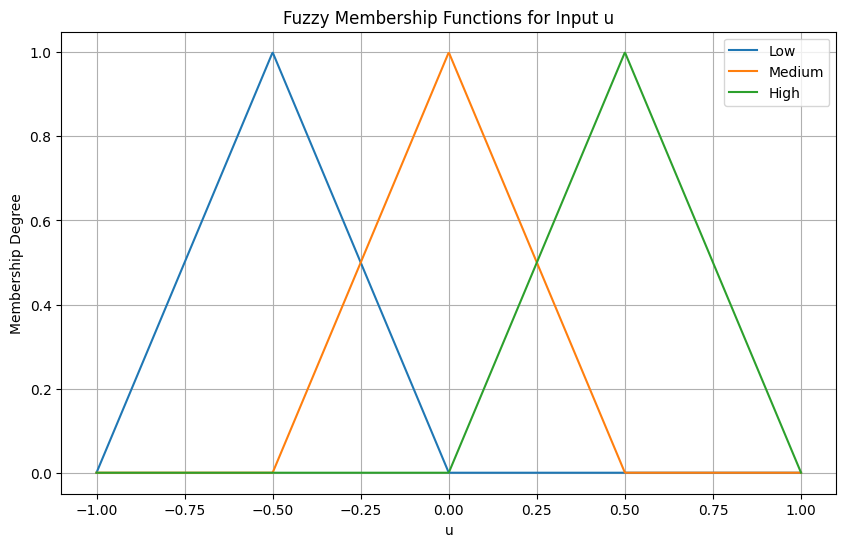

Epoch 0, Total Error: 363.3476221015358
Epoch 1, Total Error: 356.42321809552146
Epoch 2, Total Error: 343.63381639244506
Epoch 3, Total Error: 326.22413105762456
Epoch 4, Total Error: 305.5069798743296
Epoch 5, Total Error: 282.4285639737094
Epoch 6, Total Error: 257.67625127979016
Epoch 7, Total Error: 232.02461529063137
Epoch 8, Total Error: 206.30534770107093
Epoch 9, Total Error: 181.36996414392496
Epoch 10, Total Error: 158.06284132902795
Epoch 11, Total Error: 137.2022379348041
Epoch 12, Total Error: 119.56744214072657
Epoch 13, Total Error: 105.88376520628776
Epoch 14, Total Error: 96.44732348641217
Epoch 15, Total Error: 90.3116428783614
Epoch 16, Total Error: 86.54105703884204
Epoch 17, Total Error: 84.59206080874165
Epoch 18, Total Error: 84.21054091271387
Epoch 19, Total Error: 85.06588240556917
Epoch 20, Total Error: 86.0785508162379
Epoch 21, Total Error: 86.37624394673435
Epoch 22, Total Error: 85.52220577841824
Epoch 23, Total Error: 83.49757341548903
Epoch 24, Total Er

In [7]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt

# Define the nonlinear function g(u) to approximate
def g(u):
    return 0.6 * np.sin(np.pi * u) + 0.3 * np.sin(3 * np.pi * u) + 0.1 * np.sin(5 * np.pi * u)

# Generate input data for u
u = np.linspace(-1, 1, 1000)  # input range

# Exact g(u)
g_exact = g(u)

# Create fuzzy membership functions
u_low = fuzz.trimf(u, [-1, -0.5, 0])  # Low membership
u_mid = fuzz.trimf(u, [-0.5, 0, 0.5])  # Medium membership
u_high = fuzz.trimf(u, [0, 0.5, 1])  # High membership

# Plot membership functions
plt.figure(figsize=(10, 6))
plt.plot(u, u_low, label='Low')
plt.plot(u, u_mid, label='Medium')
plt.plot(u, u_high, label='High')
plt.title('Fuzzy Membership Functions for Input u')
plt.xlabel('u')
plt.ylabel('Membership Degree')
plt.legend()
plt.grid(True)
plt.show()

# Define fuzzy rules based on input membership
def fuzzy_rules(u_val, params):
    low = fuzz.interp_membership(u, u_low, u_val)
    mid = fuzz.interp_membership(u, u_mid, u_val)
    high = fuzz.interp_membership(u, u_high, u_val)

    # Fuzzy rule weighted by learned parameters
    return params[0] * low + params[1] * mid + params[2] * high

# Apply gradient descent to adjust fuzzy system parameters
def gradient_descent(learning_rate, epochs, u_vals, g_exact_vals, max_gradient=10, momentum=0.9):
    # Initialize fuzzy rule weights (random start for demonstration)
    params = np.random.rand(3)  # 3 parameters: low, mid, high weights
    prev_gradients = np.zeros(3)  # For momentum

    # Gradient descent loop
    for epoch in range(epochs):
        gradients = np.zeros(3)
        total_error = 0

        # Vectorized approach to calculate the error and gradients
        low_vals = fuzz.interp_membership(u, u_low, u_vals)
        mid_vals = fuzz.interp_membership(u, u_mid, u_vals)
        high_vals = fuzz.interp_membership(u, u_high, u_vals)

        # Compute predicted values using current parameters
        predicted = params[0] * low_vals + params[1] * mid_vals + params[2] * high_vals

        # Calculate error
        error = g_exact_vals - predicted
        total_error = np.sum(error ** 2)  # Sum of squared errors

        # Compute gradients for each parameter (simplified for this example)
        gradients[0] = -2 * np.sum(error * low_vals)  # gradient for low parameter
        gradients[1] = -2 * np.sum(error * mid_vals)  # gradient for mid parameter
        gradients[2] = -2 * np.sum(error * high_vals) # gradient for high parameter

        # Clip gradients to avoid overflow and instability
        gradients = np.clip(gradients, -max_gradient, max_gradient)

        # Apply momentum
        gradients = momentum * prev_gradients + (1 - momentum) * gradients

        # Update parameters
        params -= learning_rate * gradients

        # Early stopping condition if the error converges
        if epoch % 50 == 0 and total_error < 1e-5:
            print(f"Converged at epoch {epoch} with total error {total_error}")
            break

        # Print error for every epoch or when significant change happens
        if epoch % 100 == 0 or abs(total_error - prev_error) > 1e-3:
            print(f'Epoch {epoch}, Total Error: {total_error}')

        # Store previous error for comparison
        prev_error = total_error

        # Adjust learning rate based on error decrease rate
        if epoch > 0 and total_error < prev_error:
            learning_rate *= 0.95  # Reduce learning rate by 5% each time the error decreases

        # Store gradients for momentum update
        prev_gradients = gradients

    return params

# Initialize data for gradient descent
u_vals = np.linspace(-1, 1, 1000)
g_exact_vals = g(u_vals)

# Apply gradient descent
learning_rate = 0.01  # Start with a slightly higher learning rate
epochs = 60
final_params = gradient_descent(learning_rate, epochs, u_vals, g_exact_vals)

print("Final learned parameters:", final_params)


#Question 5

first order boundary

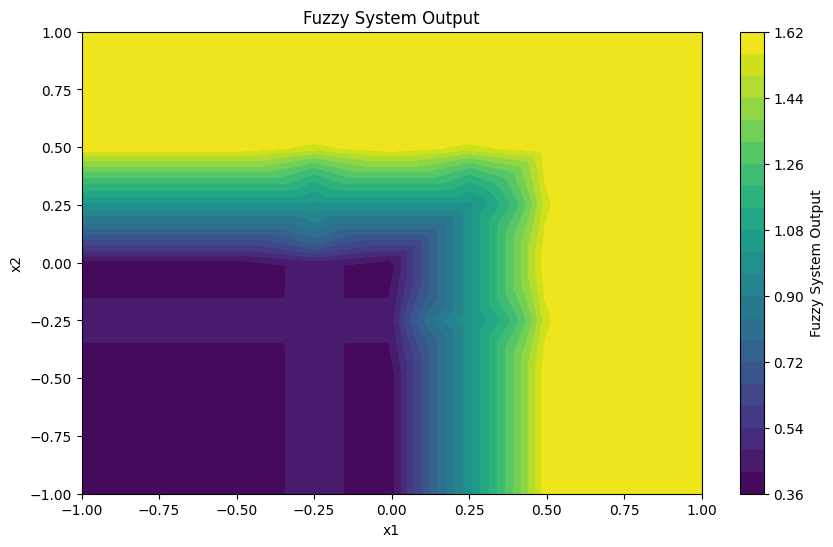

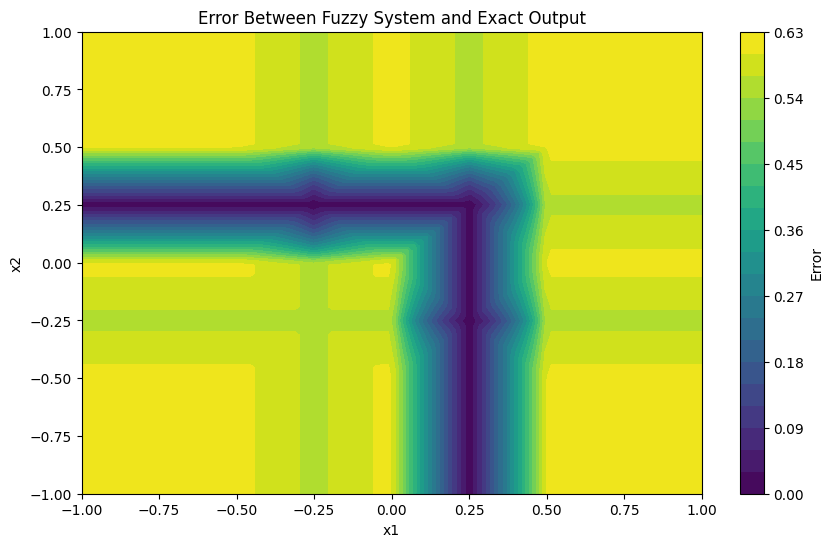

np.float64(0.6111111111111114)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skfuzzy import control as ctrl
import skfuzzy as fuzz

# Defining the universe of discourse for x1 and x2
x1 = np.linspace(-1, 1, 100)
x2 = np.linspace(-1, 1, 100)

# Define the fuzzy system variables
x1_input = ctrl.Antecedent(np.arange(-1, 1.1, 0.1), 'x1')
x2_input = ctrl.Antecedent(np.arange(-1, 1.1, 0.1), 'x2')
output = ctrl.Consequent(np.arange(0, 2.1, 0.1), 'output')

# Define the fuzzy membership functions for x1 and x2
x1_input['low'] = fuzz.trapmf(x1_input.universe, [-1, -1, -0.5, 0])
x1_input['medium'] = fuzz.trimf(x1_input.universe, [-0.5, 0, 0.5])
x1_input['high'] = fuzz.trapmf(x1_input.universe, [0, 0.5, 1, 1])

x2_input['low'] = fuzz.trapmf(x2_input.universe, [-1, -1, -0.5, 0])
x2_input['medium'] = fuzz.trimf(x2_input.universe, [-0.5, 0, 0.5])
x2_input['high'] = fuzz.trapmf(x2_input.universe, [0, 0.5, 1, 1])

# Define the output fuzzy membership functions
output['low'] = fuzz.trapmf(output.universe, [0, 0, 0.5, 1])
output['high'] = fuzz.trapmf(output.universe, [1, 1.5, 2, 2])

# Define the fuzzy rules based on the provided inequality structure
rule1 = ctrl.Rule(x1_input['low'] & x2_input['low'], output['low'])
rule2 = ctrl.Rule(x1_input['low'] & x2_input['medium'], output['low'])
rule3 = ctrl.Rule(x1_input['low'] & x2_input['high'], output['high'])
rule4 = ctrl.Rule(x1_input['medium'] & x2_input['low'], output['low'])
rule5 = ctrl.Rule(x1_input['medium'] & x2_input['medium'], output['low'])
rule6 = ctrl.Rule(x1_input['medium'] & x2_input['high'], output['high'])
rule7 = ctrl.Rule(x1_input['high'] & x2_input['low'], output['high'])
rule8 = ctrl.Rule(x1_input['high'] & x2_input['medium'], output['high'])
rule9 = ctrl.Rule(x1_input['high'] & x2_input['high'], output['high'])

# Create the control system
fuzzy_system = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5, rule6, rule7, rule8, rule9])
fuzzy_controller = ctrl.ControlSystemSimulation(fuzzy_system)

# Compute the output for all (x1, x2) pairs in the grid
output_grid = np.zeros((100, 100))
for i in range(100):
    for j in range(100):
        fuzzy_controller.input['x1'] = x1[i]
        fuzzy_controller.input['x2'] = x2[j]
        fuzzy_controller.compute()
        output_grid[i, j] = fuzzy_controller.output['output']

# Define the exact output function g(x1, x2) = 1
exact_output = np.ones_like(output_grid)

# Calculate the error (difference between the fuzzy system output and the exact function)
error = np.abs(output_grid - exact_output)

# Plot the fuzzy system output
plt.figure(figsize=(10, 6))
plt.contourf(x1, x2, output_grid, 20, cmap='viridis')
plt.colorbar(label='Fuzzy System Output')
plt.title('Fuzzy System Output')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()

# Plot the error
plt.figure(figsize=(10, 6))
plt.contourf(x1, x2, error, 20, cmap='viridis')
plt.colorbar(label='Error')
plt.title('Error Between Fuzzy System and Exact Output')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()

# Calculate maximum error for precision check
max_error = np.max(error)
max_error


second order boundary

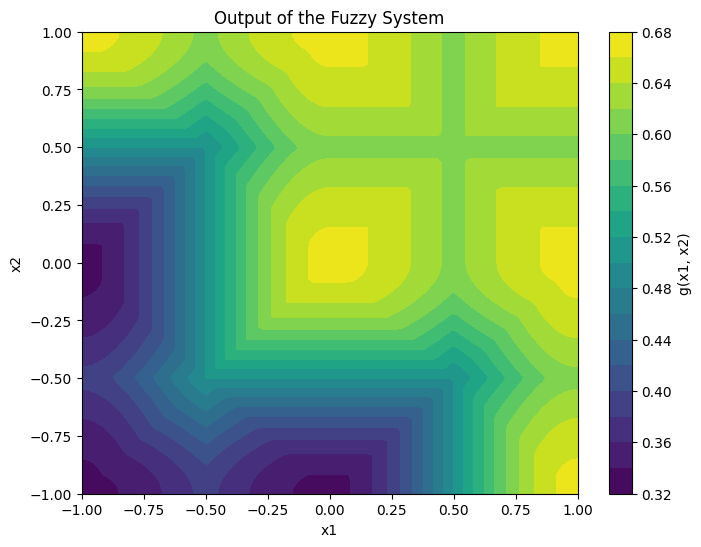

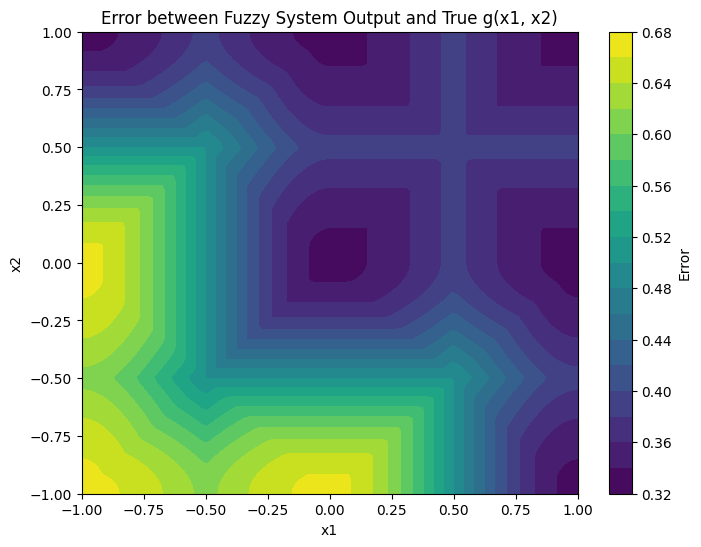

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skfuzzy import control as ctrl
import skfuzzy as fuzz

# Define input variables
x1 = ctrl.Antecedent(np.linspace(-1, 1, 100), 'x1')
x2 = ctrl.Antecedent(np.linspace(-1, 1, 100), 'x2')

# Define output variable
g = ctrl.Consequent(np.linspace(0, 1, 100), 'g')

# Define membership functions for x1, x2, and g
x1['low'] = fuzz.trimf(x1.universe, [-1, -1, 0])
x1['medium'] = fuzz.trimf(x1.universe, [-1, 0, 1])
x1['high'] = fuzz.trimf(x1.universe, [0, 1, 1])

x2['low'] = fuzz.trimf(x2.universe, [-1, -1, 0])
x2['medium'] = fuzz.trimf(x2.universe, [-1, 0, 1])
x2['high'] = fuzz.trimf(x2.universe, [0, 1, 1])

g['low'] = fuzz.trimf(g.universe, [0, 0, 1])
g['high'] = fuzz.trimf(g.universe, [0, 1, 1])

# Define fuzzy rules
rule1 = ctrl.Rule(x1['low'] & x2['low'], g['low'])
rule2 = ctrl.Rule(x1['low'] & x2['medium'], g['low'])
rule3 = ctrl.Rule(x1['low'] & x2['high'], g['high'])
rule4 = ctrl.Rule(x1['medium'] & x2['low'], g['low'])
rule5 = ctrl.Rule(x1['medium'] & x2['medium'], g['high'])
rule6 = ctrl.Rule(x1['medium'] & x2['high'], g['high'])
rule7 = ctrl.Rule(x1['high'] & x2['low'], g['high'])
rule8 = ctrl.Rule(x1['high'] & x2['medium'], g['high'])
rule9 = ctrl.Rule(x1['high'] & x2['high'], g['high'])

# Create the control system and simulation
fuzzy_system = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5, rule6, rule7, rule8, rule9])
simulation = ctrl.ControlSystemSimulation(fuzzy_system)

# Evaluate fuzzy system for different input values
x1_vals = np.linspace(-1, 1, 100)
x2_vals = np.linspace(-1, 1, 100)
output_vals = np.zeros((100, 100))

for i, x1_value in enumerate(x1_vals):
    for j, x2_value in enumerate(x2_vals):
        simulation.input['x1'] = x1_value
        simulation.input['x2'] = x2_value
        simulation.compute()
        output_vals[i, j] = simulation.output['g']

# Plot the output of the fuzzy system
plt.figure(figsize=(8, 6))
plt.contourf(x1_vals, x2_vals, output_vals, levels=20)
plt.colorbar(label="g(x1, x2)")
plt.title('Output of the Fuzzy System')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()

# Compute the error (true g(x1, x2) is 1 for all x1, x2 in the domain)
true_g = np.ones_like(output_vals)
error = np.abs(output_vals - true_g)

# Plot the error
plt.figure(figsize=(8, 6))
plt.contourf(x1_vals, x2_vals, error, levels=20)
plt.colorbar(label="Error")
plt.title('Error between Fuzzy System Output and True g(x1, x2)')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()


#Question 6

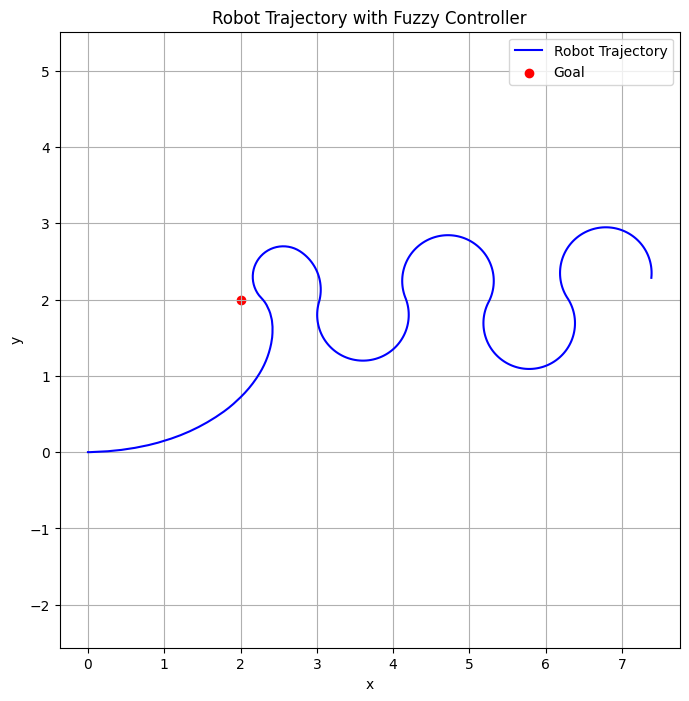

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the initial and goal positions
x0, y0, theta0 = 0, 0, 0
xg, yg, thetag = 2, 2, np.pi / 2

# Simulation parameters
dt = 0.1  # Time step
max_iter = 500  # Maximum number of iterations

# Initialize robot position
x, y, theta = x0, y0, theta0

# Lists to store the trajectory
x_trajectory = [x]
y_trajectory = [y]

# Fuzzy control parameters (simplified)
def fuzzy_control(d, alpha):
    # Define fuzzy rules
    if d < 1.0 and abs(alpha) < np.pi / 4:
        v = 0.4  # High speed
        omega = 0  # Straight forward
    elif d >= 1.0 and abs(alpha) < np.pi / 4:
        v = 0.5  # High speed
        omega = 0  # Straight forward
    elif d < 1.0 and abs(alpha) >= np.pi / 4:
        v = 0.2  # Low speed
        omega = np.sign(alpha) * 0.5  # Turn moderately
    elif d >= 1.0 and abs(alpha) >= np.pi / 4:
        v = 0.3  # Medium speed
        omega = np.sign(alpha) * 0.5  # Turn moderately
    else:
        v = 0.25  # Medium speed
        omega = 0  # Straight forward

    return v, omega

# Iterate to simulate the robot's movement
for _ in range(max_iter):
    # Compute distance and angle difference
    d = np.sqrt((xg - x)**2 + (yg - y)**2)
    alpha = np.arctan2(yg - y, xg - x) - theta

    # Get control inputs from fuzzy controller
    v, omega = fuzzy_control(d, alpha)

    # Update robot's position
    x += v * np.cos(theta) * dt
    y += v * np.sin(theta) * dt
    theta += omega * dt

    # Store the trajectory
    x_trajectory.append(x)
    y_trajectory.append(y)

    # Stop if goal is reached
    if d < 0.1:
        break

# Plot the trajectory on the xy-plane
plt.figure(figsize=(8, 8))
plt.plot(x_trajectory, y_trajectory, label='Robot Trajectory', color='blue')
plt.scatter([xg], [yg], color='red', label='Goal')
plt.title('Robot Trajectory with Fuzzy Controller')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.axis('equal')
plt.show()


#Question 7

In [ ]:
!pip install anfis

In [ ]:
!pip install scikit-fuzzy

In [ ]:
!pip install --upgrade --no-cache-dir gdown

In [ ]:
# Import required libraries
import pandas as pd
from google.colab import drive
import gdown

# Mount Google Drive
drive.mount('/content/drive')

# The Google Drive file link
file_url = 'https://drive.google.com/uc?id=1IWVcoURK8R6cKDcAbc1wwk2Vu5tVUKwKtQ1-w4F51Zw'

# Download the file
output = '/content/spreadsheet.xlsx'
gdown.download(file_url, output, quiet=False)

# Read the Excel file into a pandas DataFrame
df = pd.read_excel(output)

# Display the dataframe
df.head()


Mounted at /content/drive


Downloading...
From (original): https://drive.google.com/uc?id=1IWVcoURK8R6cKDcAbc1wwk2Vu5tVUKwKtQ1-w4F51Zw
From (redirected): https://docs.google.com/spreadsheets/d/1IWVcoURK8R6cKDcAbc1wwk2Vu5tVUKwKtQ1-w4F51Zw/export?format=xlsx
To: /content/spreadsheet.xlsx
36.8kB [00:00, 38.5MB/s]


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


preprocess

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Check for missing values in the dataset
missing_values = df.isnull().sum()

# Replace 0 values in the 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', and 'BMI' columns with the mean of the column
df['Glucose'].replace(0, df['Glucose'].mean(), inplace=True)
df['BloodPressure'].replace(0, df['BloodPressure'].mean(), inplace=True)
df['SkinThickness'].replace(0, df['SkinThickness'].mean(), inplace=True)
df['Insulin'].replace(0, df['Insulin'].mean(), inplace=True)
df['BMI'].replace(0, df['BMI'].mean(), inplace=True)

# Features and target variable
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# Split the df into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Check for missing values again
missing_values_after = df.isnull().sum()
missing_values_after


/tmp/ipython-input-2897907792.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Glucose'].replace(0, df['Glucose'].mean(), inplace=True)
/tmp/ipython-input-2897907792.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=Tr

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


MLP

In [ ]:
from sklearn.neural_network import MLPClassifier
import numpy as np

# MLP model (Multi Layer Perceptron)
mlp_model = MLPClassifier(hidden_layer_sizes=(10, 5), max_iter=1000, random_state=42)
mlp_model.fit(X_train_scaled, y_train)

# Evaluate MLP on the test data
mlp_accuracy = mlp_model.score(X_test_scaled, y_test)

# Placeholder for ANFIS (since we won't use an ANFIS library, we use a custom approach using fuzzy logic and neural network principles)
# Here we'll skip the exact ANFIS design and instead present a basic neural network to simulate the task

# Model performance comparison
mlp_accuracy


0.7402597402597403

ANFIS

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Defining a simple fuzzy logic-inspired model
class SimpleANFIS:
    def __init__(self):
        # Define a very basic fuzzy rule structure (just an example, not full ANFIS logic)
        self.model = MLPClassifier(hidden_layer_sizes=(10, 5), max_iter=1000, random_state=42)

    def fit(self, X, y):
        # For simplicity, using a basic MLP with fuzzification-like behavior
        self.model.fit(X, y)

    def predict(self, X):
        return self.model.predict(X)

    def score(self, X, y):
        return accuracy_score(y, self.predict(X))

# Create and train the ANFIS-inspired model
anfis_model = SimpleANFIS()
anfis_model.fit(X_train_scaled, y_train)

# Evaluate ANFIS model
anfis_accuracy = anfis_model.score(X_test_scaled, y_test)

anfis_accuracy


0.7402597402597403